100%|██████████| 170M/170M [21:56<00:00, 130kB/s]


Using device: cpu
Training samples: 50000

Training with SGD + Momentum
Epoch 1/10 - Loss: 1.7039, Accuracy: 39.89%
Epoch 2/10 - Loss: 1.4821, Accuracy: 48.21%
Epoch 3/10 - Loss: 1.3808, Accuracy: 52.07%
Epoch 4/10 - Loss: 1.3101, Accuracy: 54.50%
Epoch 5/10 - Loss: 1.2565, Accuracy: 56.28%
Epoch 6/10 - Loss: 1.2039, Accuracy: 58.13%
Epoch 7/10 - Loss: 1.1566, Accuracy: 59.84%
Epoch 8/10 - Loss: 1.1160, Accuracy: 61.26%
Epoch 9/10 - Loss: 1.0746, Accuracy: 62.66%
Epoch 10/10 - Loss: 1.0384, Accuracy: 63.77%

Training with Adam
Epoch 1/10 - Loss: 1.6402, Accuracy: 42.51%
Epoch 2/10 - Loss: 1.4352, Accuracy: 49.84%
Epoch 3/10 - Loss: 1.3415, Accuracy: 53.20%
Epoch 4/10 - Loss: 1.2790, Accuracy: 55.55%
Epoch 5/10 - Loss: 1.2237, Accuracy: 57.69%
Epoch 6/10 - Loss: 1.1666, Accuracy: 59.52%
Epoch 7/10 - Loss: 1.1143, Accuracy: 61.44%
Epoch 8/10 - Loss: 1.0740, Accuracy: 63.01%
Epoch 9/10 - Loss: 1.0253, Accuracy: 64.53%
Epoch 10/10 - Loss: 0.9812, Accuracy: 66.20%


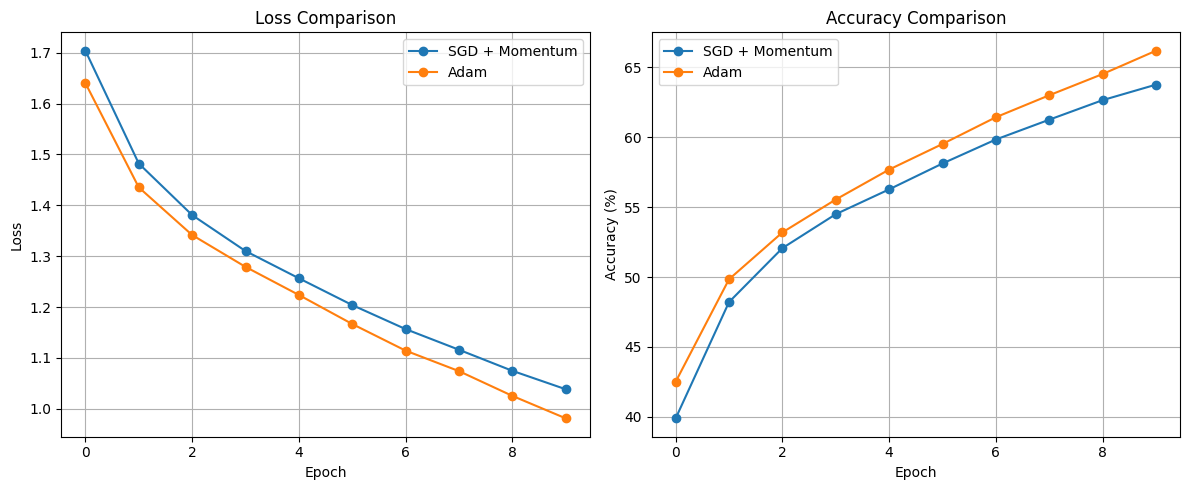


Final Results
SGD + Momentum - Loss: 1.0384, Accuracy: 63.77%
Adam - Loss: 0.9812, Accuracy: 66.20%


In [ ]:
# ==========================================
# Exp-3: Comparison of SGD with Momentum vs Adam Optimizer
# ==========================================

# Step 1: Import Necessary Libraries

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt


# Step 2: Set Device and Load Dataset

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

trainset = torchvision.datasets.CIFAR10(
    root='./data',
    train=True,
    transform=transform,
    download=True
)

trainloader = torch.utils.data.DataLoader(
    trainset,
    batch_size=128,
    shuffle=True
)

print("Using device:", device)
print("Training samples:", len(trainset))


# Step 3: Define the MLP Model

class MLP(nn.Module):

    def __init__(self):
        super().__init__()

        self.flatten = nn.Flatten()

        self.network = nn.Sequential(
            nn.Linear(3 * 32 * 32, 256),
            nn.ReLU(),
            nn.Linear(256, 10)
        )

    def forward(self, x):

        x = self.flatten(x)

        return self.network(x)


# Step 4: Define the Training Function

def train_model(model, optimizer, epochs=10):

    model.to(device)

    loss_function = nn.CrossEntropyLoss()

    losses = []
    accuracies = []

    for epoch in range(epochs):

        total_loss = 0
        correct = 0
        total = 0

        model.train()

        for images, labels in trainloader:

            images = images.to(device)
            labels = labels.to(device)

            # Forward propagation
            outputs = model(images)

            # Calculate loss
            loss = loss_function(outputs, labels)

            # Backpropagation
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            total_loss += loss.item()

            # Calculate accuracy
            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

        average_loss = total_loss / len(trainloader)
        accuracy = 100 * correct / total

        losses.append(average_loss)
        accuracies.append(accuracy)

        print(
            f"Epoch {epoch + 1}/{epochs} - "
            f"Loss: {average_loss:.4f}, "
            f"Accuracy: {accuracy:.2f}%"
        )

    return losses, accuracies


# Step 5: Train Model using SGD with Momentum

model_sgd = MLP()

sgd_optimizer = optim.SGD(
    model_sgd.parameters(),
    lr=0.01,
    momentum=0.9
)

print("\nTraining with SGD + Momentum")

losses_sgd, accuracy_sgd = train_model(
    model_sgd,
    sgd_optimizer
)


# Step 6: Train Model using Adam Optimizer

model_adam = MLP()

adam_optimizer = optim.Adam(
    model_adam.parameters(),
    lr=0.001
)

print("\nTraining with Adam")

losses_adam, accuracy_adam = train_model(
    model_adam,
    adam_optimizer
)


# Step 7: Compare Loss and Accuracy

plt.figure(figsize=(12, 5))

# Loss comparison
plt.subplot(1, 2, 1)

plt.plot(
    losses_sgd,
    marker='o',
    label='SGD + Momentum'
)

plt.plot(
    losses_adam,
    marker='o',
    label='Adam'
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss Comparison")

plt.legend()
plt.grid(True)


# Accuracy comparison
plt.subplot(1, 2, 2)

plt.plot(
    accuracy_sgd,
    marker='o',
    label='SGD + Momentum'
)

plt.plot(
    accuracy_adam,
    marker='o',
    label='Adam'
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Accuracy Comparison")

plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


# Step 8: Display Final Results

print("\nFinal Results")

print(
    f"SGD + Momentum - "
    f"Loss: {losses_sgd[-1]:.4f}, "
    f"Accuracy: {accuracy_sgd[-1]:.2f}%"
)

print(
    f"Adam - "
    f"Loss: {losses_adam[-1]:.4f}, "
    f"Accuracy: {accuracy_adam[-1]:.2f}%"
)